# Tugas Praproses Data — House Prices (train.csv)
**5054251048 – Sulaiman Faiz Tsaqib**

## 1. Import Dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('train (1).csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
print(df.shape)
df.info()

(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## 2. Pembersihan Data

In [3]:
miss = df.isna().mean().mul(100).round(2)
miss[miss > 0].sort_values(ascending=False)

PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtQual         2.53
BsmtCond         2.53
BsmtFinType1     2.53
MasVnrArea       0.55
Electrical       0.07
dtype: float64

In [4]:
# hapus kolom dengan missing > 50%
drop_cols = miss[miss > 50].index
df = df.drop(columns=drop_cols)
print('Dihapus:', list(drop_cols))

Dihapus: ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature']


Sisa nilai hilang diisi: **median** untuk numerik (tahan outlier), **modus** untuk kategorik.

In [5]:
df['MSSubClass'] = df['MSSubClass'].astype(str)  # kode kategori, bukan angka
num = df.select_dtypes('number').columns.drop(['Id', 'SalePrice'])
cat = df.select_dtypes(exclude='number').columns

df[num] = df[num].fillna(df[num].median())
df[cat] = df[cat].fillna(df[cat].mode().iloc[0])
print('Sisa missing:', df.isna().sum().sum())

Sisa missing: 0


## 3. Deteksi & Penanganan Outlier

EnclosedPorch    208
BsmtFinSF2       167
OverallCond      125
ScreenPorch      116
LotFrontage      106
MasVnrArea        98
BsmtHalfBath      82
OpenPorchSF       77
dtype: int64

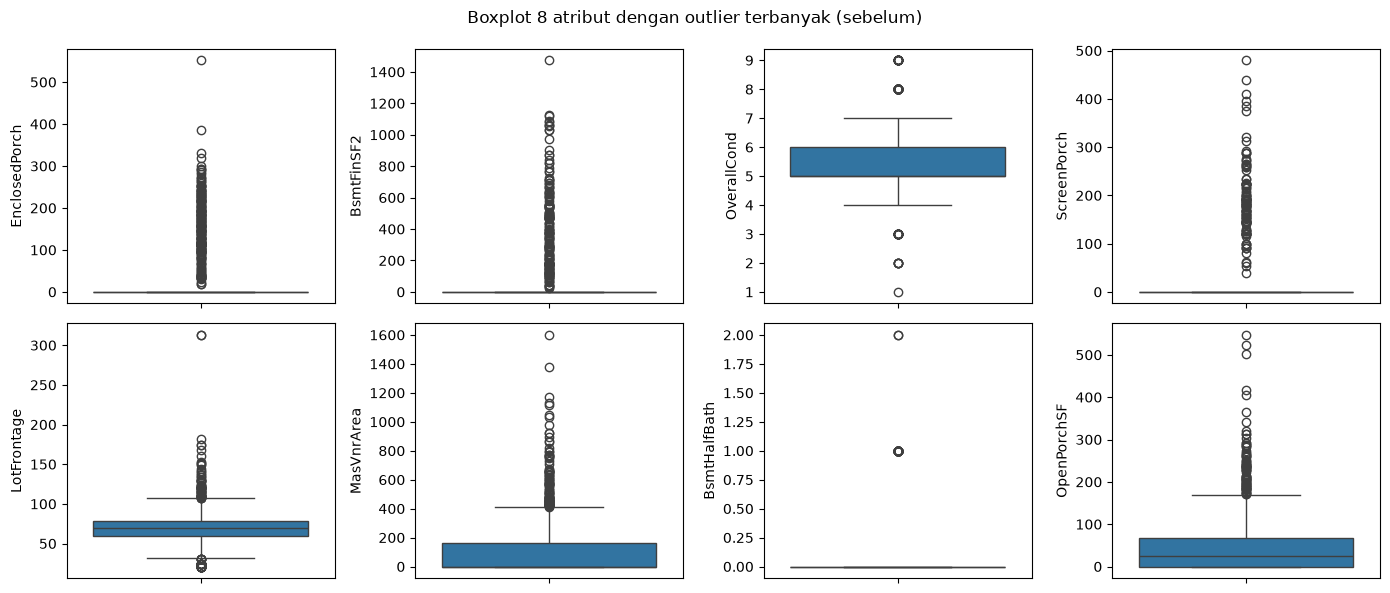

In [6]:
q1, q3 = df[num].quantile(.25), df[num].quantile(.75)
iqr = q3 - q1
low, up = q1 - 1.5*iqr, q3 + 1.5*iqr
n_out = ((df[num] < low) | (df[num] > up)).sum().sort_values(ascending=False)

top = n_out.index[:8]
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for a, c in zip(ax.ravel(), top):
    sns.boxplot(y=df[c], ax=a)
plt.suptitle('Boxplot 8 atribut dengan outlier terbanyak (sebelum)'); plt.tight_layout()
n_out.head(8)

**Keputusan:** outlier **disesuaikan (capping/winsorizing ke batas IQR)**, tidak dihapus. Alasan: data hanya 1460 baris, sehingga penghapusan akan membuang banyak informasi; nilai ekstrem (mis. rumah sangat luas) adalah nilai nyata, bukan error, jadi cukup dibatasi pengaruhnya.

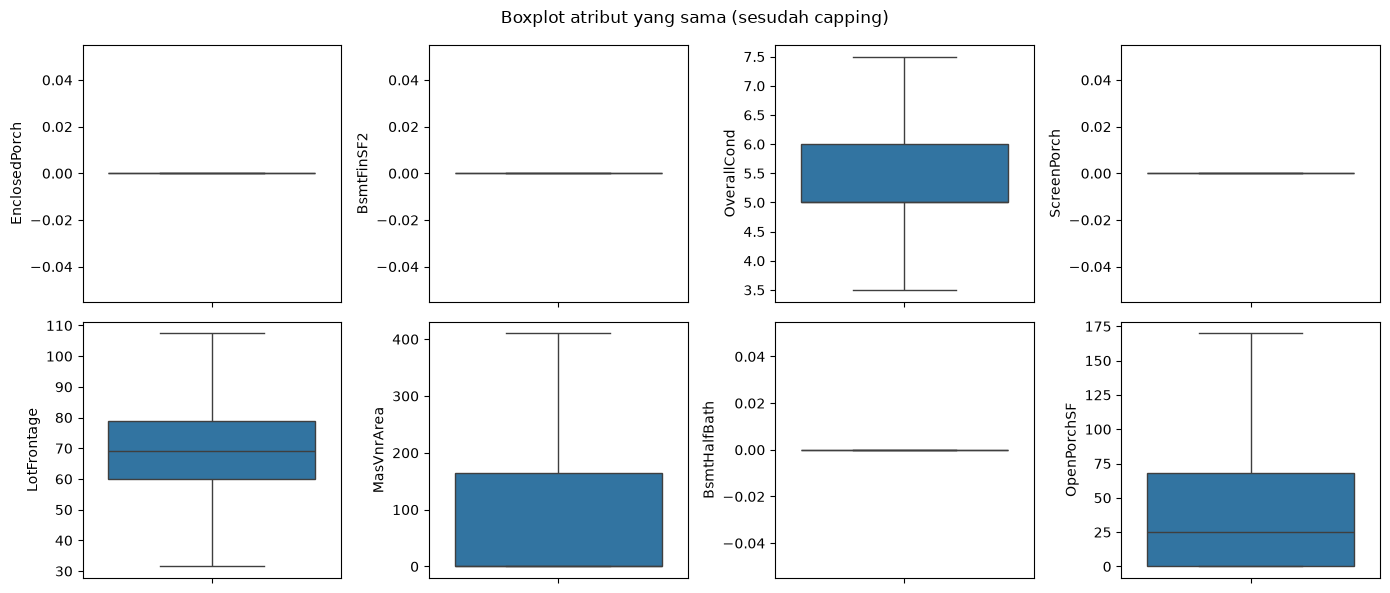

In [7]:
df[num] = df[num].clip(low, up, axis=1)

fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for a, c in zip(ax.ravel(), top):
    sns.boxplot(y=df[c], ax=a)
plt.suptitle('Boxplot atribut yang sama (sesudah capping)'); plt.tight_layout()

## 4. Transformasi Data

In [8]:
# standarisasi numerik (mean 0, std 1); kolom konstan setelah capping dibuang
num = [c for c in num if df[c].nunique() > 1]
df[num] = StandardScaler().fit_transform(df[num])

# one-hot encoding kategorik
df = pd.get_dummies(df, columns=cat, dtype=int)
print(df.shape)
df.iloc[:, :8].head()

(1460, 287)


,Id,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea
0,1,-0.237456,-0.333244,0.652644,-0.564161,1.053246,0.878668,0.795643
1,2,0.633321,-0.013189,-0.073068,2.030907,0.156179,-0.429577,-0.667353
2,3,-0.063300,0.446022,0.652644,-0.564161,0.986797,0.830215,0.541858
3,4,-0.527714,-0.027104,0.652644,-0.564161,-1.870528,-0.720298,-0.667353
4,5,0.865528,1.283733,1.378355,-0.564161,0.953572,0.733308,1.945140


## 5. Reduksi Dimensi

### 5a. Analisis Korelasi

Dibuang (|r| > 0.8): ['1stFlrSF', 'TotRmsAbvGrd', 'GarageArea']
(1460, 284)


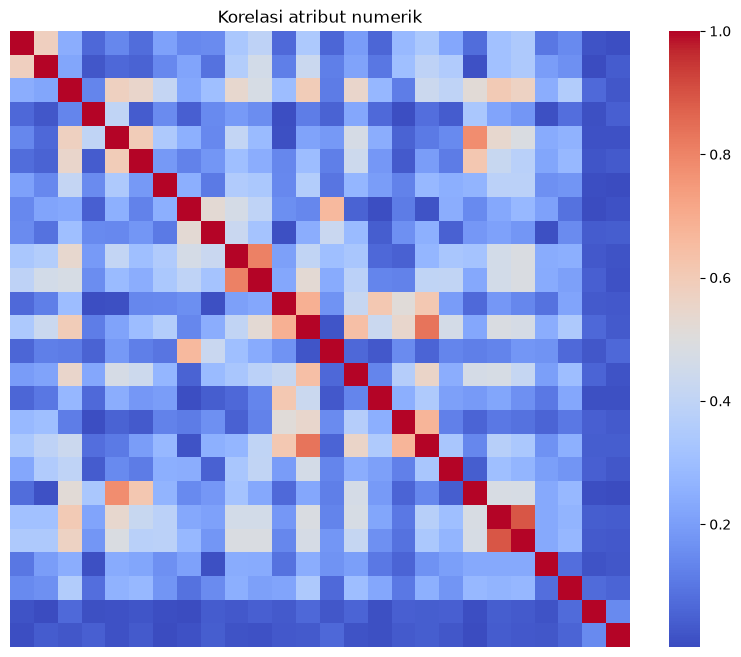

In [9]:
corr = df[num].corr().abs()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, cmap='coolwarm', xticklabels=False, yticklabels=False)
plt.title('Korelasi atribut numerik')

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = [c for c in upper if (upper[c] > 0.8).any()]
print('Dibuang (|r| > 0.8):', high)
df = df.drop(columns=high)
print(df.shape)

### 5b. PCA

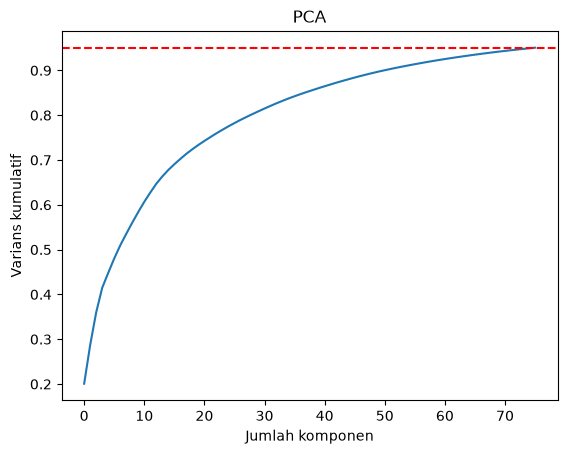

282 fitur -> 76 komponen (95% varians)


In [10]:
X = df.drop(columns=['Id', 'SalePrice'])
pca = PCA(n_components=0.95).fit(X)
X_pca = pca.transform(X)

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.axhline(.95, color='r', ls='--'); plt.xlabel('Jumlah komponen'); plt.ylabel('Varians kumulatif')
plt.title('PCA'); plt.show()
print(f'{X.shape[1]} fitur -> {pca.n_components_} komponen (95% varians)')

## 6. Dataset Akhir

In [11]:
final = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])
final['SalePrice'] = df['SalePrice'].values
print(final.shape, '| missing:', final.isna().sum().sum())
final.to_csv('train_preprocessed.csv', index=False)
final.head()

(1460, 77) | missing: 0


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC68,PC69,PC70,PC71,PC72,PC73,PC74,PC75,PC76,SalePrice
0,2.484935,0.060118,-1.266343,-2.533234,-1.020287,1.175979,0.099715,-1.726612,0.144032,-0.162115,...,0.383383,-0.028183,0.066330,0.043674,0.043532,-0.040748,-0.030538,-0.006927,0.115531,208500
1,-0.133019,-1.146494,1.559120,0.257251,1.298230,0.573736,-0.750607,1.746957,-0.376489,-0.104925,...,-0.763710,-0.075658,0.174123,0.206169,0.018685,-0.448157,0.355116,-0.108620,-0.040882,181500
2,3.083843,0.532599,-0.448480,-1.758582,-0.514362,-0.241199,-0.811312,-0.277936,0.115818,0.059562,...,0.619088,0.059423,0.083787,-0.048067,-0.024376,-0.087379,-0.253860,0.058083,0.142366,223500
3,-0.693927,1.055103,0.496753,-0.393769,0.083906,-0.576711,0.352310,-0.722130,0.195362,-2.181467,...,-0.272371,-0.161977,0.304077,-0.081035,0.497368,-0.543957,-0.143657,0.094667,0.134499,140000
4,5.087071,1.285633,1.183990,-1.202115,-0.415284,-0.785340,-0.907565,0.096698,-0.419374,1.386317,...,-0.553425,0.095751,-0.235574,-0.001710,-0.066165,0.060407,0.233501,-0.062622,-0.210432,250000
